In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams['figure.figsize'] = (14, 7)
plt.rcParams['font.size'] = 10
plt.rcParams['font.family'] = 'DejaVu Sans'  

In [3]:
df = pd.read_csv('owid-co2-data.csv')
print(df.head())

        Entity Code  Year  Annual CO₂ emissions
0  Afghanistan  AFG  1949               14656.0
1  Afghanistan  AFG  1950               84272.0
2  Afghanistan  AFG  1951               91600.0
3  Afghanistan  AFG  1952               91600.0
4  Afghanistan  AFG  1953              106256.0


In [4]:
n_rows, n_cols = df.shape
print(f"→ Общая размерность датасета: {n_rows:,} строк × {n_cols} столбцов\n")

print("→ Техническая информация о датасете:\n")
df.info()

→ Общая размерность датасета: 29,384 строк × 4 столбцов

→ Техническая информация о датасете:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29384 entries, 0 to 29383
Data columns (total 4 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Entity                29384 non-null  object 
 1   Code                  23714 non-null  object 
 2   Year                  29384 non-null  int64  
 3   Annual CO₂ emissions  29384 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 918.4+ KB


In [5]:
print("\n Обнаружение пропущенных значений:\n")
missing_data = df.isnull().sum()
has_missing = False
for col in missing_data.index:
    if missing_data[col] > 0:
        has_missing = True
        pct = (missing_data[col] / len(df)) * 100
        print(f"  {col}: {missing_data[col]:,} пропусков ({pct:.1f}%)")
if not has_missing:
    print("   Пропуски отсутствуют")



 Обнаружение пропущенных значений:

  Code: 5,670 пропусков (19.3%)


In [6]:
print("\n→ Базовая статистика:\n")
print(df[['Year', 'Annual CO₂ emissions']].describe())


→ Базовая статистика:

               Year  Annual CO₂ emissions
count  29384.000000          2.938400e+04
mean    1948.359243          4.202270e+08
std       59.148142          1.972092e+09
min     1750.000000          0.000000e+00
25%     1913.000000          3.810560e+05
50%     1963.000000          5.080756e+06
75%     1995.000000          5.365634e+07
max     2024.000000          3.859858e+10


In [7]:
initial_size = len(df)

In [8]:
df_clean = df.dropna(subset=['Code']).copy()
removed_no_code = initial_size - len(df_clean)
print(f" Удалено записей без кода страны: {removed_no_code:,}")


df_clean = df_clean[df_clean['Entity'] != 'World']
removed_world = len(df) - removed_no_code - len(df_clean)
print(f" Удалены мировые агрегаты: {removed_world:,}")

print(f"\n Финальный размер датасета: {len(df_clean):,} записей ({len(df_clean)/initial_size*100:.1f}% от исходного)")


 Удалено записей без кода страны: 5,670
 Удалены мировые агрегаты: 275

 Финальный размер датасета: 23,439 записей (79.8% от исходного)


###  ЗАДАЧА №1: Страна с максимальными выбросами

In [20]:

emissions_by_country = df_clean.groupby('Entity')['Annual CO₂ emissions'].sum().sort_values(ascending=False)


top_emitter = emissions_by_country.index[0]
top_emissions_value = emissions_by_country.iloc[0]

print(f"РЕЗУЛЬТАТ: {top_emitter}")
print(f"   Совокупные выбросы: {top_emissions_value:,.0f} тонн CO₂")
print(f"   В гигатоннах: {top_emissions_value / 1e9:.2f} Гт\n")


print("ТОП-10 СТРАН ПО ВЫБРОСАМ:\n")
for position, (nation, value) in enumerate(emissions_by_country.head(10).items(), start=1):
    gt_value = value / 1e9
    print(f"  {position:2} {nation:28}  {value:20,.0f} т  {gt_value:8.2f} Гт")


РЕЗУЛЬТАТ: United States
   Совокупные выбросы: 434,866,568,350 тонн CO₂
   В гигатоннах: 434.87 Гт

ТОП-10 СТРАН ПО ВЫБРОСАМ:

   1 United States                      434,866,568,350 т    434.87 Гт
   2 China                              285,087,038,068 т    285.09 Гт
   3 Russia                             122,808,231,943 т    122.81 Гт
   4 Germany                             95,135,675,962 т     95.14 Гт
   5 United Kingdom                      80,079,446,353 т     80.08 Гт
   6 Japan                               69,612,279,266 т     69.61 Гт
   7 India                               66,072,530,817 т     66.07 Гт
   8 France                              40,047,568,498 т     40.05 Гт
   9 Canada                              35,644,130,844 т     35.64 Гт
  10 Ukraine                             31,236,494,637 т     31.24 Гт


### ЗАДАЧА №2: Анализ выбросов по десятилетиям

In [10]:
df_clean['Decade'] = (df_clean['Year'] // 10) * 10

emissions_by_decade = df_clean.groupby('Decade')['Annual CO₂ emissions'].sum()

print("ВЫБРОСЫ ПО ДЕСЯТИЛЕТИЯМ:\n")
for period, amount in emissions_by_decade.items():
    gt = amount / 1e9
    year_range = f"{period}–{period+9}"
    print(f"  {year_range}  {amount:24,.0f} т  {gt:10.2f} Гт")

print("\nТЕМПЫ РОСТА:\n")
growth = emissions_by_decade.pct_change() * 100
for period, rate in growth.items():
    if not np.isnan(rate):
        direction = "▲" if rate > 0 else "▼"
        print(f"  {period}-е  {direction} {abs(rate):6.1f}% по сравнению с предыдущей декадой")


ВЫБРОСЫ ПО ДЕСЯТИЛЕТИЯМ:

  1750–1759                97,914,934 т        0.10 Гт
  1760–1769               115,722,073 т        0.12 Гт
  1770–1779               142,642,063 т        0.14 Гт
  1780–1789               177,649,313 т        0.18 Гт
  1790–1799               225,193,814 т        0.23 Гт
  1800–1809               338,391,250 т        0.34 Гт
  1810–1819               444,598,243 т        0.44 Гт
  1820–1829               591,596,306 т        0.59 Гт
  1830–1839               952,335,011 т        0.95 Гт
  1840–1849             1,486,962,157 т        1.49 Гт
  1850–1859             2,483,303,860 т        2.48 Гт
  1860–1869             4,210,496,819 т        4.21 Гт
  1870–1879             6,581,098,084 т        6.58 Гт
  1880–1889            10,230,381,820 т       10.23 Гт
  1890–1899            15,064,007,612 т       15.06 Гт
  1900–1909            24,212,319,213 т       24.21 Гт
  1910–1919            32,775,964,035 т       32.78 Гт
  1920–1929            37,061,114,245 т

### ЗАДАЧА №3: Континентальный анализ

In [11]:
geo_classification = {

    'China': 'АЗИЯ', 'India': 'АЗИЯ', 'Japan': 'АЗИЯ', 'South Korea': 'АЗИЯ',
    'Indonesia': 'АЗИЯ', 'Saudi Arabia': 'АЗИЯ', 'Iran': 'АЗИЯ', 'Thailand': 'АЗИЯ',
    'Pakistan': 'АЗИЯ', 'Malaysia': 'АЗИЯ', 'Vietnam': 'АЗИЯ', 'Philippines': 'АЗИЯ',
    'Bangladesh': 'АЗИЯ', 'Iraq': 'АЗИЯ', 'Kazakhstan': 'АЗИЯ', 'United Arab Emirates': 'АЗИЯ',
    'Taiwan': 'АЗИЯ', 'Singapore': 'АЗИЯ', 'Israel': 'АЗИЯ', 'Hong Kong': 'АЗИЯ',
    

    'Russia': 'ЕВРОПА', 'Germany': 'ЕВРОПА', 'United Kingdom': 'ЕВРОПА', 'France': 'ЕВРОПА',
    'Italy': 'ЕВРОПА', 'Poland': 'ЕВРОПА', 'Spain': 'ЕВРОПА', 'Ukraine': 'ЕВРОПА',
    'Netherlands': 'ЕВРОПА', 'Belgium': 'ЕВРОПА', 'Czech Republic': 'ЕВРОПА', 'Romania': 'ЕВРОПА',
    'Greece': 'ЕВРОПА', 'Austria': 'ЕВРОПА', 'Sweden': 'ЕВРОПА', 'Finland': 'ЕВРОПА',
    'Portugal': 'ЕВРОПА', 'Denmark': 'ЕВРОПА', 'Norway': 'ЕВРОПА', 'Switzerland': 'ЕВРОПА',
    'Ireland': 'ЕВРОПА', 'Bulgaria': 'ЕВРОПА', 'Hungary': 'ЕВРОПА', 'Serbia': 'ЕВРОПА',
    

    'United States': 'СЕВ. АМЕРИКА', 'Canada': 'СЕВ. АМЕРИКА', 'Mexico': 'СЕВ. АМЕРИКА',

    'Brazil': 'ЮЖ. АМЕРИКА', 'Argentina': 'ЮЖ. АМЕРИКА', 'Venezuela': 'ЮЖ. АМЕРИКА',
    'Colombia': 'ЮЖ. АМЕРИКА', 'Chile': 'ЮЖ. АМЕРИКА', 'Peru': 'ЮЖ. АМЕРИКА',
    

    'South Africa': 'АФРИКА', 'Egypt': 'АФРИКА', 'Algeria': 'АФРИКА', 'Nigeria': 'АФРИКА',
    'Morocco': 'АФРИКА', 'Libya': 'АФРИКА', 'Kenya': 'АФРИКА', 'Ethiopia': 'АФРИКА',
    

    'Australia': 'ОКЕАНИЯ', 'New Zealand': 'ОКЕАНИЯ'
}


In [12]:
df_clean['Continent'] = df_clean['Entity'].map(geo_classification)


df_geo = df_clean[df_clean['Continent'].notna()].copy()


current_year = df_geo['Year'].max()
current_snapshot = df_geo[df_geo['Year'] == current_year]


continental_emissions = current_snapshot.groupby('Continent')['Annual CO₂ emissions'].sum().sort_values(ascending=False)

print(f"РАСПРЕДЕЛЕНИЕ ВЫБРОСОВ ({int(current_year)} год):")
print(f"База анализа: {len(geo_classification)} ключевых стран-эмитентов\n")

aggregate_total = continental_emissions.sum()
for region, emission_vol in continental_emissions.items():
    gt_vol = emission_vol / 1e9
    proportion = (emission_vol / aggregate_total) * 100
    print(f"  {region:15}  {emission_vol:18,.0f} т  {gt_vol:6.2f} Гт  {proportion:5.1f}%")


dominant_region = continental_emissions.index[0]
dominant_volume = continental_emissions.iloc[0]



РАСПРЕДЕЛЕНИЕ ВЫБРОСОВ (2024 год):
База анализа: 63 ключевых стран-эмитентов

  АЗИЯ                 21,861,812,964 т   21.86 Гт   62.5%
  СЕВ. АМЕРИКА          5,898,447,750 т    5.90 Гт   16.9%
  ЕВРОПА                4,594,059,830 т    4.59 Гт   13.1%
  АФРИКА                1,205,610,680 т    1.21 Гт    3.4%
  ЮЖ. АМЕРИКА           1,011,744,812 т    1.01 Гт    2.9%
  ОКЕАНИЯ                 419,211,812 т    0.42 Гт    1.2%


In [13]:

print(f" ЛИДЕР: {dominant_region:57} ")
print(f" Объём выбросов: {dominant_volume:,.0f} т ({dominant_volume/1e9:.2f} Гт)".ljust(69) )
print(f" Доля: {(dominant_volume/aggregate_total)*100:.1f}% от анализируемого массива".ljust(69))




print("ИСТОРИЧЕСКАЯ ПЕРСПЕКТИВА (1750-2017)")

historical_continental = df_geo.groupby('Continent')['Annual CO₂ emissions'].sum().sort_values(ascending=False)

print("СУММАРНЫЕ ИСТОРИЧЕСКИЕ ВЫБРОСЫ:\n")
for region, total_vol in historical_continental.items():
    gt_total = total_vol / 1e9
    print(f"  {region:15}  {total_vol:20,.0f} т  {gt_total:10.2f} Гт")

 ЛИДЕР: АЗИЯ                                                      
 Объём выбросов: 21,861,812,964 т (21.86 Гт)                         
 Доля: 62.5% от анализируемого массива                               
ИСТОРИЧЕСКАЯ ПЕРСПЕКТИВА (1750-2017)
СУММАРНЫЕ ИСТОРИЧЕСКИЕ ВЫБРОСЫ:

  АЗИЯ                  575,284,334,231 т      575.28 Гт
  ЕВРОПА                519,964,972,523 т      519.96 Гт
  СЕВ. АМЕРИКА          492,526,550,877 т      492.53 Гт
  АФРИКА                 45,872,938,829 т       45.87 Гт
  ЮЖ. АМЕРИКА            44,525,438,787 т       44.53 Гт
  ОКЕАНИЯ                22,052,017,550 т       22.05 Гт


# ГЕНЕРАЦИЯ ВИЗУАЛИЗАЦИЙ

# Визуализация 1: Декадная динамика

 Создана визуализация: viz_1_декады.png


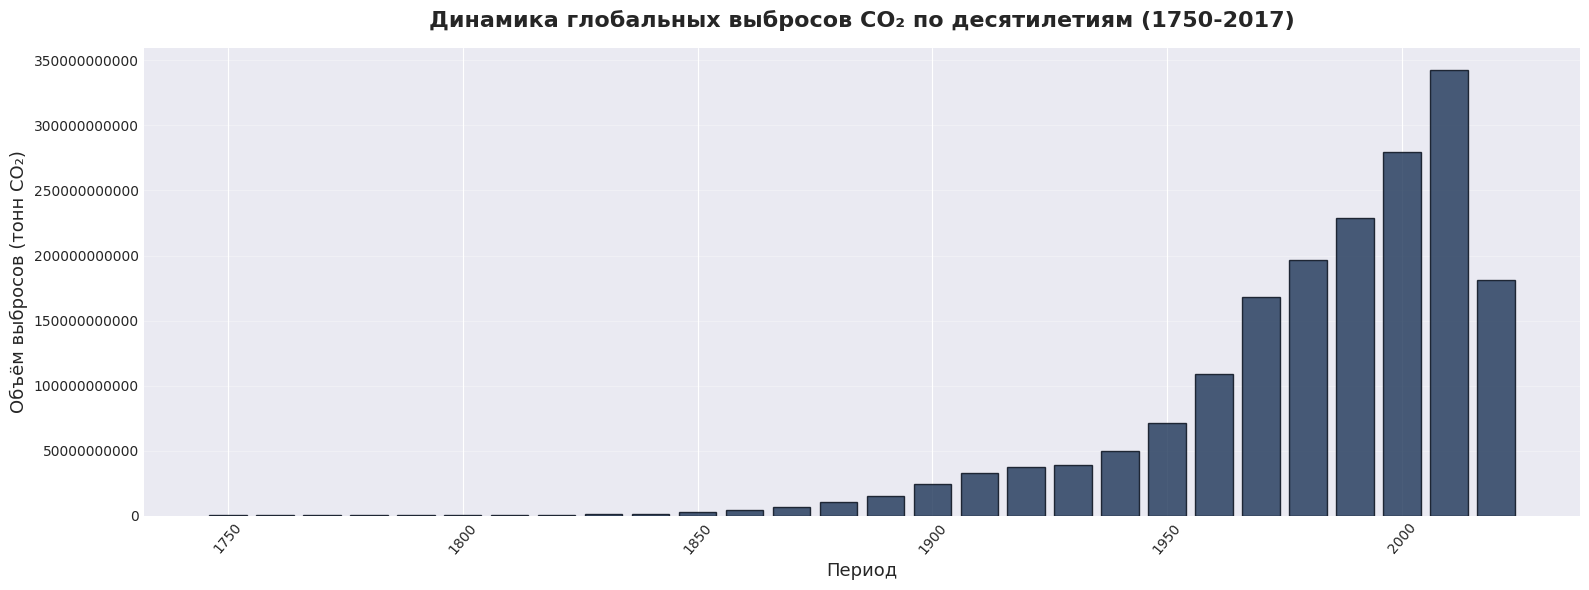

In [14]:
fig, ax = plt.subplots(figsize=(16, 6))
ax.bar(emissions_by_decade.index, emissions_by_decade.values, 
       color='#1D3557', edgecolor='#000814', alpha=0.8, width=8)
ax.set_title('Динамика глобальных выбросов CO₂ по десятилетиям (1750-2017)', 
             fontsize=16, fontweight='bold', pad=15)
ax.set_xlabel('Период', fontsize=13)
ax.set_ylabel('Объём выбросов (тонн CO₂)', fontsize=13)
ax.tick_params(axis='x', rotation=50)
ax.grid(axis='y', alpha=0.3)
ax.ticklabel_format(style='plain', axis='y')
plt.tight_layout()
plt.savefig('viz_1_декады.png', dpi=300, bbox_inches='tight')
print(" Создана визуализация: viz_1_декады.png")
plt.show()

# Визуализация 2: Страны-лидеры

 Создана визуализация: viz_2_рейтинг_стран.png


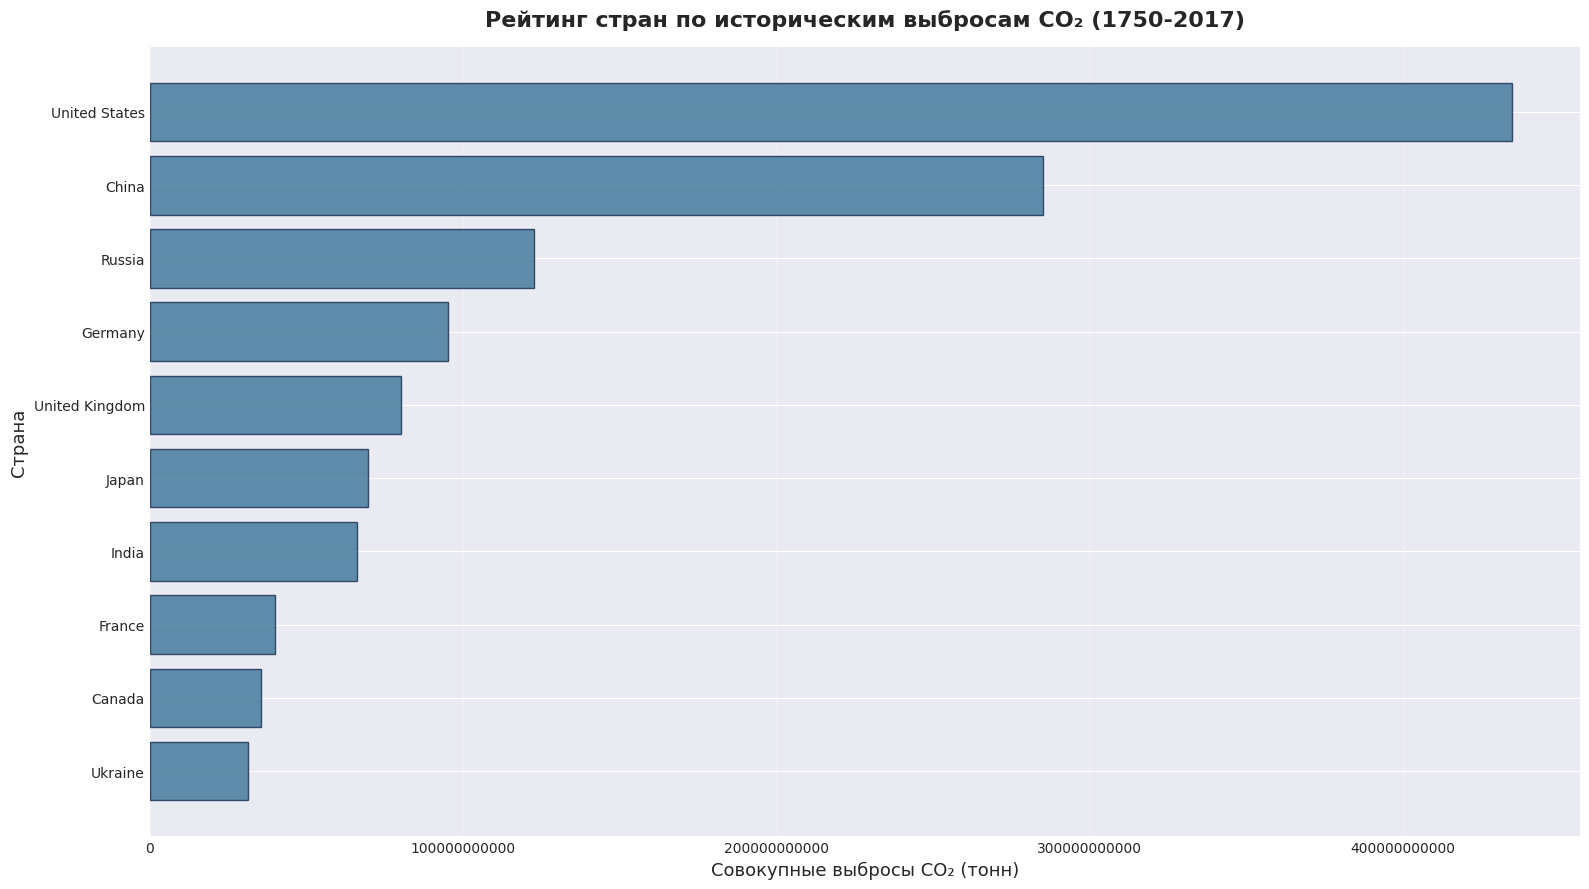

In [15]:
fig, ax = plt.subplots(figsize=(16, 9))
top_10 = emissions_by_country.head(10)
ax.barh(range(len(top_10)), top_10.values, 
        color='#457B9D', edgecolor='#1D3557', alpha=0.85)
ax.set_yticks(range(len(top_10)))
ax.set_yticklabels(top_10.index)
ax.set_xlabel('Совокупные выбросы CO₂ (тонн)', fontsize=13)
ax.set_ylabel('Страна', fontsize=13)
ax.set_title('Рейтинг стран по историческим выбросам CO₂ (1750-2017)', 
             fontsize=16, fontweight='bold', pad=15)
ax.invert_yaxis()
ax.grid(axis='x', alpha=0.3)
ax.ticklabel_format(style='plain', axis='x')
plt.tight_layout()
plt.savefig('viz_2_рейтинг_стран.png', dpi=300, bbox_inches='tight')
print(" Создана визуализация: viz_2_рейтинг_стран.png")
plt.show()

# Визуализация 3: Временные ряды топ-5

 Создана визуализация: viz_3_временные_ряды.png


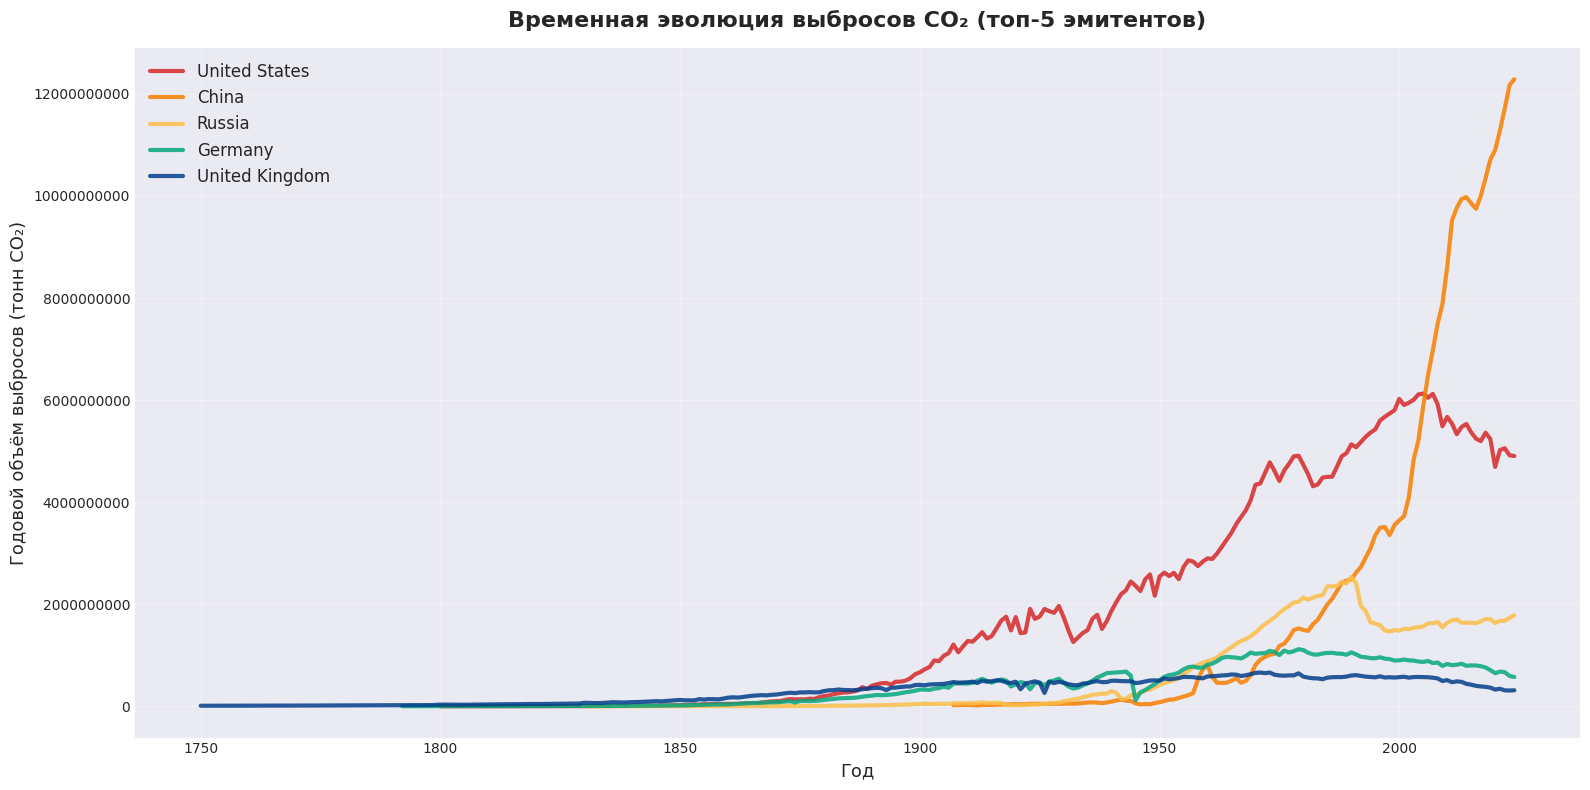

In [16]:
fig, ax = plt.subplots(figsize=(16, 8))
top_5 = emissions_by_country.head(5).index
color_scheme = ['#D62828', '#F77F00', '#FCBF49', '#06A77D', '#023E8A']

for idx, country in enumerate(top_5):
    time_series = df_clean[df_clean['Entity'] == country].sort_values('Year')
    ax.plot(time_series['Year'], time_series['Annual CO₂ emissions'], 
            linewidth=3, label=country, alpha=0.85, color=color_scheme[idx])

ax.set_title('Временная эволюция выбросов CO₂ (топ-5 эмитентов)', 
             fontsize=16, fontweight='bold', pad=15)
ax.set_xlabel('Год', fontsize=13)
ax.set_ylabel('Годовой объём выбросов (тонн CO₂)', fontsize=13)
ax.legend(loc='upper left', fontsize=12, framealpha=0.95)
ax.grid(True, alpha=0.3)
ax.ticklabel_format(style='plain', axis='y')
plt.tight_layout()
plt.savefig('viz_3_временные_ряды.png', dpi=300, bbox_inches='tight')
print(" Создана визуализация: viz_3_временные_ряды.png")
plt.show()

# Визуализация 4: Континентальное распределение

 Создана визуализация: viz_4_континенты.png


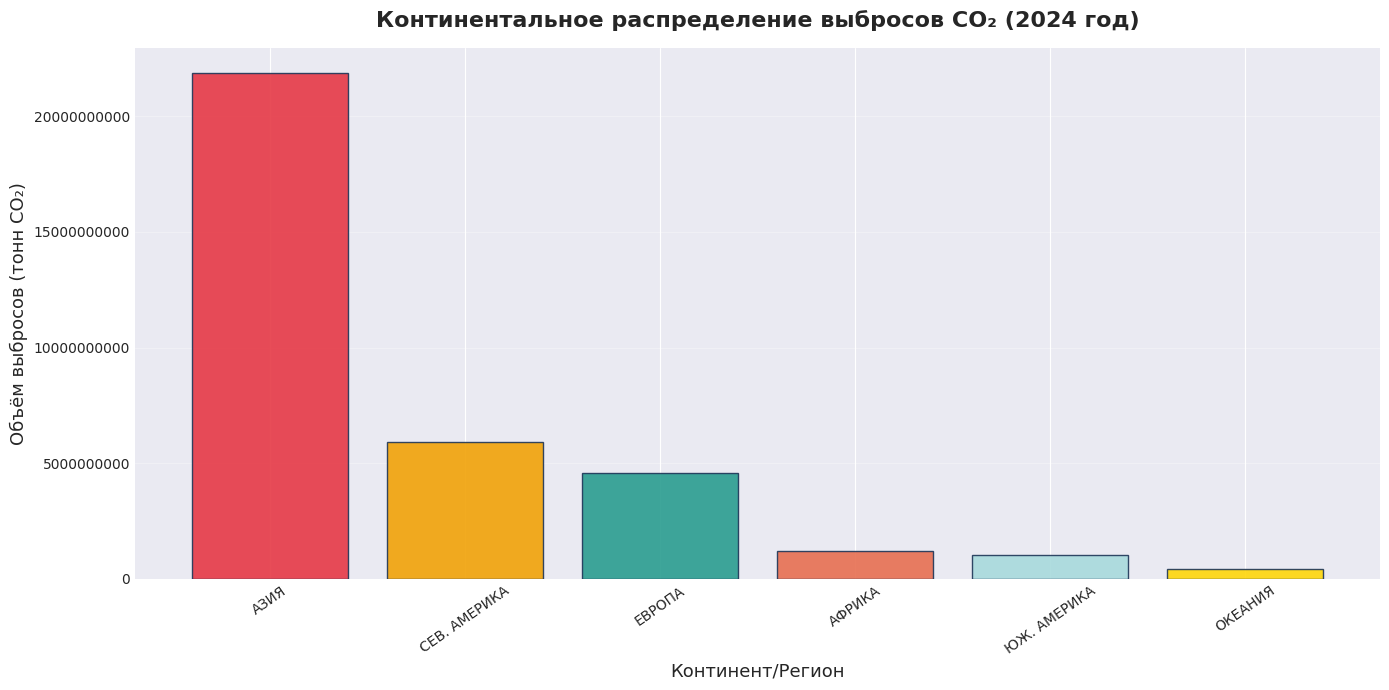

In [17]:
fig, ax = plt.subplots(figsize=(14, 7))
color_palette = ['#E63946', '#F1A208', '#2A9D8F', '#E76F51', '#A8DADC', '#FFD60A']
ax.bar(continental_emissions.index, continental_emissions.values, 
       color=color_palette[:len(continental_emissions)], 
       edgecolor='#1D3557', alpha=0.9)
ax.set_title(f'Континентальное распределение выбросов CO₂ ({int(current_year)} год)', 
             fontsize=16, fontweight='bold', pad=15)
ax.set_xlabel('Континент/Регион', fontsize=13)
ax.set_ylabel('Объём выбросов (тонн CO₂)', fontsize=13)
ax.tick_params(axis='x', rotation=35)
ax.grid(axis='y', alpha=0.3)
ax.ticklabel_format(style='plain', axis='y')
plt.tight_layout()
plt.savefig('viz_4_континенты.png', dpi=300, bbox_inches='tight')
print(" Создана визуализация: viz_4_континенты.png")
plt.show()

In [18]:

print("РАБОТА ЗАВЕРШЕНА")

print("Итоговые материалы:")
print("  • viz_1_декады.png")
print("  • viz_2_рейтинг_стран.png")
print("  • viz_3_временные_ряды.png")
print("  • viz_4_континенты.png\n")
print("Статус: Все задачи выполнены ")


РАБОТА ЗАВЕРШЕНА
Итоговые материалы:
  • viz_1_декады.png
  • viz_2_рейтинг_стран.png
  • viz_3_временные_ряды.png
  • viz_4_континенты.png

Статус: Все задачи выполнены 
